# Entrenamiento - reconocimiento de emociones

En este cuaderno se aborda el reconocimiento de emociones faciales mediante diferentes enfoques. Concretamente, se comparan:

* **SVM**: modelo clásico aplicado directamente sobre los píxeles de las imágenes.
* **Eigenfaces (PCA) + SVM**: SVM tras aplicar PCA para reducir el número de características de entrada en el entrenamiento.
* **Fisherfaces (PCA + LDA) + SVM**: similar al experimento anterior, pero que suele aportar mejores resultados al incluir reducción supervisada.
* **HOG + SVM** y **LBP + SVM**: SVM aplicando distintos tipos de descriptores locales.
* **ResNet-18**: _transfer learning_ a partir de esta CNN preentrenada en ImageNet.
* **DeepFace.analyze**: modelo original de DeepFace.
* **DeepFace reentrenada**: red usada por `DeepFace.analyze` y reentrenada con el nuevo conjunto de datos.

## Evaluación

Todos los modelos se evalúan en las mismas condiciones:

- **Datos:** [FER2013](https://www.kaggle.com/datasets/deadskull7/fer2013?select=fer2013.csv), con caras en escala de grises de 48 × 48 píxeles clasificadas en 7 emociones. Es el _dataset_ con el que se entrenó el modelo de emociones de [DeepFace](https://huggingface.co/nxp/deepface-emotion-imx). Además, se utiliza [FER+](https://github.com/microsoft/FERPlus), pues reetiqueta de forma más precisa las imágenes de FER2013.
- **Validación en entrenamiento:** 5-fold sobre los conjuntos de _Training_ y _PublicTest_ del conjunto de datos original.
- **Métricas:** _accuracy_, F1-macro y F1 de cada emoción sobre el conjunto _PrivateTest_ del _dataset_ original.

## Índice

1. [Preparación](#1-preparación)
2. [Datos](#2-datos)
    - [2.1 FER2013 y FER+](#21-fer2013-y-fer)
    - [2.2 _Folds_](#22-folds)
3. [Entrenamiento](#3-entrenamiento)
    - [3.1 ResNet-18 con _transfer learning_](#31-resnet-18-con-transfer-learning)
    - [3.2 Reentrenamiento de DeepFace](#32-reentrenamiento-de-deepface)
    - [3.3 Modelos clásicos](#33-modelos-clásicos)
        - [3.3.1 Ajuste de C y gamma](#331-ajuste-de-c-y-gamma)
        - [3.3.2 Entrenamiento de los _folds_](#332-entrenamiento-de-los-folds)
4. [Evaluación](#4-evaluación)
    - [4.1 DeepFace.analyze](#41-deepfaceanalyze)
    - [4.2 Tasa de acierto](#42-tasa-de-acierto)
    - [4.3 Robustez](#43-robustez)
    - [4.4 Coste](#44-coste)
5. [Conclusiones](#5-conclusiones)

## 1. Preparación

Antes de ejecutar este _notebook_, se debe descargar [`fer2013.csv`](https://www.kaggle.com/datasets/deadskull7/fer2013) y ubicarlo en `prac5/data/fer2013/`.

In [2]:
import copy
import pickle
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.tensorboard import SummaryWriter

sys.path.insert(0, "..")
from common.benchmark import measure_latency
from common.classification_metrics import classification_metrics, plot_confusion_matrix
from common.emotions.classical import classical_model, feature_extractor, tune_svm
from common.emotions.data import EMOTIONS, compute_class_weights, fold_splits, load_fer2013, load_ferplus_labels
from common.emotions.images import PERTURBATIONS, augment, to_unit
from common.emotions.model import DeepFaceAnalyze, DeepFaceEmotion, ResNetEmotion, TorchEmotionPredictor
from common.experiment import RESULTS, ROOT, WEIGHTS, cached, load_config
from common.training import GPUBatchLoader, Trainer, seed_everything

cfg = load_config("emotions.yaml")
RESULTS_DIR = RESULTS / "emotions"
WEIGHTS_DIR = WEIGHTS / "emotions"
RUNS_DIR = ROOT / "runs" / "emotions"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

torch.backends.cudnn.benchmark = True
print(torch.cuda.get_device_name())

NVIDIA GeForce RTX 5080


## 2. Datos

### 2.1 FER2013 y FER+

Como ya se ha mencionado anteriormente, FER2013 divide las imágenes en 3 subconjuntos **Training**, **PublicTest** y **PrivateTest**.

[FER+](https://github.com/microsoft/FERPlus) mantiene las mismas imágenes utilizadas por FER2013, pero las reetiqueta para generar anotaciones más precisas. Cada imagen se reetiqueta por 10 personas, y se utiliza la emoción más elegida entre la identificadas.

Todos los modelos se entrenan y evalúan con las dos versiones de etiquetado.

Anotaciones por emoción en cada partición:

In [3]:
images, fer2013_labels, usage = load_fer2013()
LABELSETS = {"FER2013": fer2013_labels, "FER+": load_ferplus_labels()}
LABELSET_IDS = {"FER2013": "fer2013", "FER+": "ferplus"}
is_test = usage == "PrivateTest"

distribution = pd.DataFrame({(name, part): np.bincount(labels[(is_test == test) & (labels >= 0)], minlength=len(EMOTIONS))
                             for name, labels in LABELSETS.items() for part, test in (("k-fold", False), ("test", True))},
                            index=EMOTIONS)
distribution.loc["total"] = distribution.sum()
display(distribution)

FER2013         FER+      
          k-fold  test k-fold  test
angry       4462   491   3050   359
disgust      492    55    276    28
fear        4593   528    900   116
happy       8110   879   8514   933
sad         5483   594   4371   480
surprise    3586   416   3920   430
neutral     5572   626  10722  1173
total      32298  3589  31753  3519

Ejemplos de caras de cada emoción:

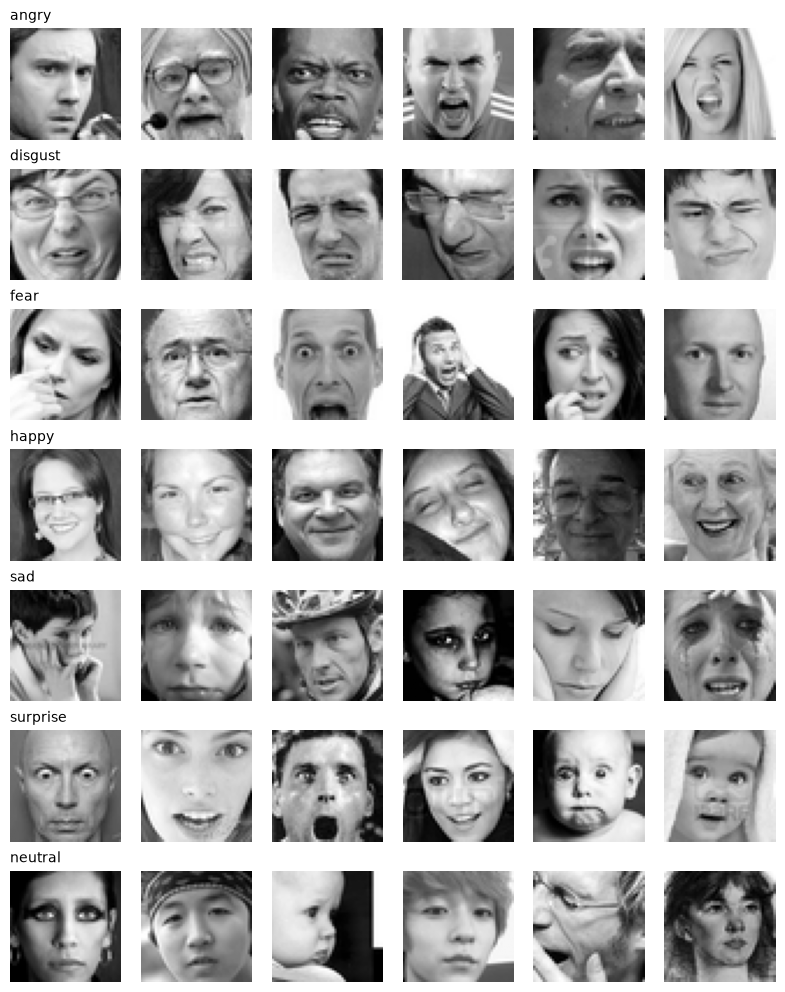

In [4]:
fig, axes = plt.subplots(len(EMOTIONS), 6, figsize=(8, 10))
for emotion, row in enumerate(axes):
    for ax, i in zip(row, np.flatnonzero(fer2013_labels == emotion)[:6]):
        ax.imshow(images[i], cmap="gray")
        ax.axis("off")
    row[0].set_title(EMOTIONS[emotion], loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ejemplos_por_clase.png", dpi=120)
plt.show()

### 2.2 _Folds_

Se realiza un 5-fold utilizando los subconjuntos _Training_ + _PublicTest_ (32,298 caras). Estos se dividen de forma equitativa, para que cada _fold_ tenga la misma proporción de cada emoción. Por ejemplo, la distribución por emoción en el fold de validación de cada iteración:

In [5]:
def split(labels):
    known = labels >= 0
    trainval, test = np.flatnonzero(known & ~is_test), np.flatnonzero(known & is_test)
    folds = [(trainval[train], trainval[val]) for train, val in fold_splits(labels[trainval], cfg.n_folds, cfg.seed)]
    return folds, test


splits = {name: split(labels) for name, labels in LABELSETS.items()}
display(pd.DataFrame({f"fold {i}": np.bincount(fer2013_labels[val], minlength=len(EMOTIONS))
                      for i, (_, val) in enumerate(splits["FER2013"][0])}, index=EMOTIONS))

,fold 0,fold 1,fold 2,fold 3,fold 4
angry,893,893,892,892,892
disgust,98,99,99,98,98
fear,918,918,919,919,919
happy,1622,1622,1622,1622,1622
sad,1097,1097,1097,1096,1096
surprise,718,717,717,717,717
neutral,1114,1114,1114,1115,1115


## 3. Entrenamiento

### 3.1 ResNet-18 con _transfer learning_

Se ha seleccionado ResNet-18 frente a arquitecturas más complejas, teniendo en cuenta la baja resolución de las imágenes y su representación en escala de grises. De esta forma, se busca mantener un equilibrio entre la capacidad de aprendizaje del modelo y su coste computacional.

- Se parte de los pesos de **ImageNet** y se cambia el clasificador para adaptarlo a las **7 salidas** requeridas.
- En el **_transfer learning_** implementado, se entrena únicamente el clasificador durante las 2 primeras épocas, y a partir de la tercera se entrena la red entera. El objetivo es mantener un entrenamiento estable.
- Se aplica **_data augmentation_** con las siguientes transformaciones aleatorias: _flip_ horizontal, rotación de hasta ±10°, zoom entre 0,9-1,1×, desplazamiento de hasta el 8 % del tamaño de la imagen, y brillo y contraste de ±20 %.
- Se aplican pesos para cada clase, con el fin de paliar el desbalanceo.
- **Optimizador:** AdamW, con _learning rates_ distintos para las distintas partes de la red (más bajo para la parte convolutiva, y más alto para el clasificador), nuevamente para estabilizar el conocimiento ya adquirido de la red. La tasa de aprendizaje también varía con el tiempo.
- **_Early stopping_:** tras cada época se mide el F1-macro en el _fold_ de validación. Se detiene anticipadamente el entrenamiento si el resultado no mejora durante 8 épocas seguidas.
- Al terminar, la ResNet-18 del mejor _fold_ de cada etiquetado se guarda en `weights/emotions/resnet18_fer2013.pt` y `resnet18_ferplus.pt`, para usarla en la demo.

Ejemplo de un _batch_ tras aplicar _data augmentation_:

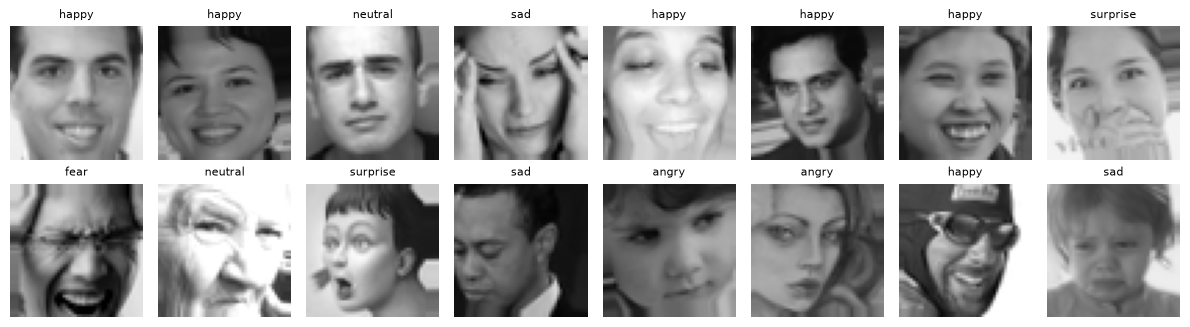

In [6]:
folds, _ = splits["FER2013"]
x, y = next(iter(GPUBatchLoader(images[folds[0][0]], fer2013_labels[folds[0][0]], 16, train=True, seed=cfg.seed)))
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, image, label in zip(axes.flat, augment(to_unit(x)).cpu().numpy(), y.cpu().numpy()):
    ax.imshow(image[0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(EMOTIONS[label], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

Código de entrenamiento de la red:

In [7]:
results, best_models = {}, {}


def train_and_pick_best(train_folds, labels, folds, test, tag):
    runs = train_folds(labels, folds, test, tag)
    models = [run.pop("model") for run in runs]
    val_f1 = [f1_score(labels[val], run["val_pred"], average="macro") for run, (_, val) in zip(runs, folds)]
    return runs, models[int(np.argmax(val_f1))]


def run_cached(labelset, key, name, train_folds):
    labels = LABELSETS[labelset]
    folds, test = splits[labelset]
    tag = f"{LABELSET_IDS[labelset]}_{key}"
    runs, best_models[(labelset, name)] = cached(WEIGHTS_DIR / f"{tag}.joblib",
                                                 lambda: train_and_pick_best(train_folds, labels, folds, test, tag))
    for run, (_, val) in zip(runs, folds):
        run["val"] = classification_metrics(labels[val], run["val_pred"], EMOTIONS)
        run["test"] = classification_metrics(labels[test], run["test_pred"], EMOTIONS)
    results[(labelset, name)] = runs


def net_trainer(build, param_groups, freeze_epochs=0):
    def train_folds(labels, folds, test, tag):
        runs = []
        for fold, (train, val) in enumerate(folds):
            seed_everything(cfg.seed + fold)
            model = build().cuda()
            weights = torch.tensor(compute_class_weights(labels[train]), dtype=torch.float32).cuda()
            freeze = (lambda epoch: model.freeze_body(epoch <= freeze_epochs)) if freeze_epochs else None
            trainer = Trainer(model, torch.optim.AdamW(param_groups(model), weight_decay=cfg.train.weight_decay),
                              nn.CrossEntropyLoss(weight=weights, label_smoothing=cfg.train.label_smoothing),
                              lambda x: augment(to_unit(x)), to_unit, WEIGHTS_DIR / "checkpoint.pt", cfg.train.patience,
                              SummaryWriter(str(RUNS_DIR / f"{tag}_fold{fold}")), freeze)
            start = time.time()
            trainer.fit(GPUBatchLoader(images[train], labels[train], cfg.batch_size, train=True, seed=cfg.seed + fold),
                        GPUBatchLoader(images[val], labels[val], cfg.batch_size), cfg.train.epochs, cfg.train.warmup_epochs)
            predictor = TorchEmotionPredictor(model, cfg.batch_size)
            runs.append({"model": predictor, "seconds": time.time() - start,
                         "val_pred": predictor.predict(images[val]), "test_pred": predictor.predict(images[test])})
        return runs
    return train_folds

### 3.2 Reentrenamiento de DeepFace

`DeepFace.analyze` usa internamente una red convolutiva pequeña, de unos 1.5 M de parámetros, que su autor entrenó con FER2013. En esta sección se parte de los pesos del modelo, públicos, y se realiza un _fine-tuning_ similar al llevado a cabo con [ResNet-18](#31-resnet-18-con-transfer-learning).

Esto permite comparar tanto el modelo original como el reentrenado, mostrando separadamente la eficacia de la arquitectura y del entrenamiento.

In [8]:
NETS = {
    "resnet18": ("ResNet-18", net_trainer(
        lambda: ResNetEmotion(cfg.resnet.img_size, cfg.resnet.dropout),
        lambda model: [{"params": model.body(), "lr": cfg.resnet.lr_body}, {"params": model.head(), "lr": cfg.resnet.lr_head}],
        cfg.resnet.freeze_epochs)),
    "deepface": ("DeepFace reentrenada", net_trainer(
        DeepFaceEmotion, lambda model: [{"params": model.parameters(), "lr": cfg.deepface.lr}])),
}
for labelset in LABELSETS:
    for key, (name, train_folds) in NETS.items():
        run_cached(labelset, key, name, train_folds)
    torch.save(best_models[(labelset, "ResNet-18")].model.state_dict(), WEIGHTS_DIR / f"resnet18_{LABELSET_IDS[labelset]}.pt")

### 3.3 Modelos clásicos

En este último entrenamiento, se utiliza **SVM** junto con distintos métodos de extracción de características:

- **Píxeles**: todos los píxeles de la imagen.
- **Eigenfaces (PCA)**: componentes características de una cara frente al promedio.
- **Fisherfaces (PCA + LDA)**: componente adicional a las _Eigenfaces_, que busca las direcciones que mejor separan las emociones.
- **HOG**: histogramas de la orientación de los bordes en celdas de 8 × 8 píxeles.
- **LBP**: histogramas de patrones locales de textura en celdas de 8 × 8 píxeles.

Por ejemplo, esta es la media frente a las primeras eigenfaces y fisherfaces del _fold_ 0:

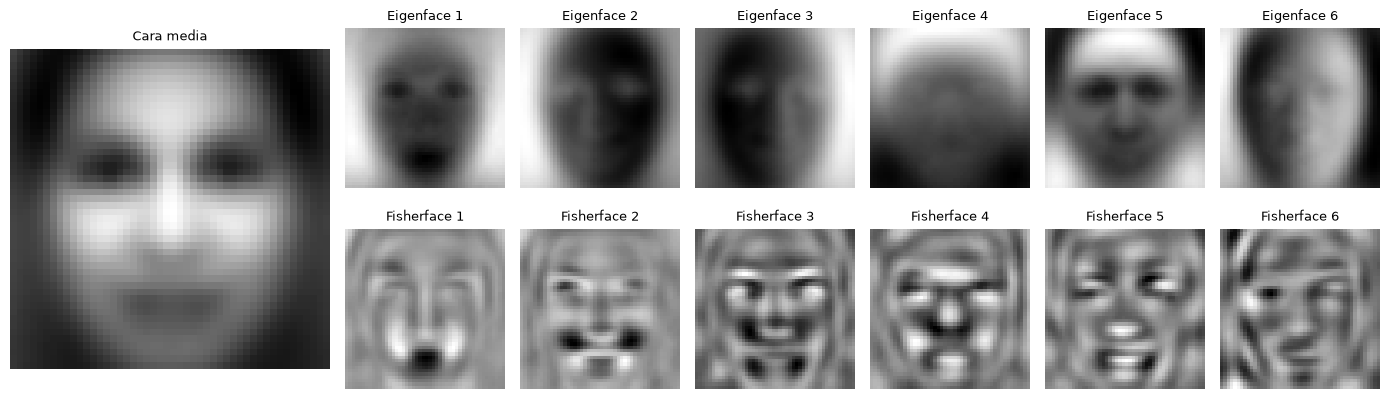

In [9]:
train = splits["FER2013"][0][0][0]
eigen = feature_extractor("eigenfaces", cfg.classical.pca_variance, cfg.seed).fit(images[train])
fisher = feature_extractor("fisherfaces", cfg.classical.pca_variance, cfg.seed).fit(images[train], fer2013_labels[train])
pca, lda = fisher[1], fisher[2]
fisherfaces = (pca.components_.T @ lda.scalings_[:, :len(EMOTIONS) - 1]).T
fig = plt.figure(figsize=(14, 4.2))
grid = fig.add_gridspec(2, 7, width_ratios=[2, 1, 1, 1, 1, 1, 1])
panels = [(grid[:, 0], "Cara media", eigen[1].mean_),]
panels += [(grid[0, i + 1], f"Eigenface {i + 1}", v) for i, v in enumerate(eigen[1].components_[:6])]
panels += [(grid[1, i + 1], f"Fisherface {i + 1}", v) for i, v in enumerate(fisherfaces)]
for spec, title, vector in panels:
    ax = fig.add_subplot(spec)
    ax.imshow(vector.reshape(48, 48), cmap="gray")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "eigenfaces_fisherfaces.png", dpi=120)
plt.show()

#### 3.3.1 Ajuste de C y gamma

El SVM tiene dos parámetros:

- **C**: exigencia en los fallos durante el entrenamiento.
- **gamma**: influencia de cada cara en el entrenamiento.

Se prueban distintas combinaciones, usando 3 valores por cada parámetro. Estos se prueban con 10.000 caras del fold 0 de FER2013, y se elige la de mayor F1-macro.

In [10]:
CLASSICAL = {"pixels": "SVM (píxeles)", "eigenfaces": "Eigenfaces + SVM", "fisherfaces": "Fisherfaces + SVM",
             "hog": "HOG + SVM", "lbp": "LBP + SVM"}


def tune_all():
    train, val = splits["FER2013"][0][0]
    subset, _ = train_test_split(train, train_size=cfg.classical.tuning_samples, stratify=fer2013_labels[train],
                                 random_state=cfg.seed)
    return {key: tune_svm(feature_extractor(key, cfg.classical.pca_variance, cfg.seed), images[subset],
                          fer2013_labels[subset], images[val], fer2013_labels[val], cfg.classical.grid_c,
                          cfg.classical.grid_gamma) for key in CLASSICAL}


tuning = cached(WEIGHTS_DIR / "svm_tuning.joblib", tune_all)
svm_params = {key: best for key, (best, _) in tuning.items()}
display(pd.concat([pd.DataFrame(scores, index=cfg.classical.grid_c,
                                columns=pd.MultiIndex.from_product([[CLASSICAL[key]], [f"gamma ×{g}" for g in cfg.classical.grid_gamma]]))
                   for key, (_, scores) in tuning.items()], axis=1).rename_axis(columns=[None, "C"]).style.format(precision=3))

#### 3.3.2 Entrenamiento de los _folds_

Con los valores elegidos se entrenan los 5 _folds_.

In [11]:
def classical_trainer(key):
    c, gamma = svm_params[key]

    def train_folds(labels, folds, test, tag):
        def one_fold(train, val):
            start = time.time()
            model = classical_model(key, c, gamma, cfg.classical.pca_variance, cfg.seed).fit(images[train], labels[train])
            return {"model": model, "seconds": time.time() - start,
                    "val_pred": model.predict(images[val]), "test_pred": model.predict(images[test])}
        return Parallel(n_jobs=len(folds), prefer="threads")(delayed(one_fold)(train, val) for train, val in folds)
    return train_folds


for key, name in CLASSICAL.items():
    Parallel(n_jobs=len(LABELSETS), prefer="threads")(
        delayed(run_cached)(labelset, key, name, classical_trainer(key)) for labelset in LABELSETS)

## 4. Evaluación

### 4.1 DeepFace.analyze

`DeepFace.analyze` se evalúa 1 sola vez al no haberse entrenado. Se evalúa sobre el subconjunto _PrivateTest_, y ejecutado con el motor de PyTorch para poder utilizar la GPU.

In [12]:
analyze = DeepFaceAnalyze("cuda")
analyze_pred = np.full(len(images), -1)
analyze_pred[is_test] = cached(WEIGHTS_DIR / "deepface_analyze_privatetest.joblib", lambda: analyze.predict(images[is_test]))
for labelset, labels in LABELSETS.items():
    test = splits[labelset][1]
    results[(labelset, "DeepFace.analyze")] = [{"seconds": np.nan, "test_pred": analyze_pred[test],
                                                "test": classification_metrics(labels[test], analyze_pred[test], EMOTIONS)}]
    best_models[(labelset, "DeepFace.analyze")] = analyze

### 4.2 Tasa de acierto

Media ± desviación típica de los 5 folds en el PrivateTest salvo `DeepFace.analyze`, que da un único resultado.

In [13]:
MODELS = list(CLASSICAL.values()) + ["ResNet-18", "DeepFace reentrenada", "DeepFace.analyze"]


def mean_std(runs, metric):
    values = [run["test"][metric] for run in runs]
    return f"{np.mean(values):.3f}" + (f" ± {np.std(values):.3f}" if len(values) > 1 else "")


accuracy = pd.DataFrame({(labelset, title): {name: mean_std(results[(labelset, name)], metric)
                                             for name in MODELS if (labelset, name) in results}
                         for labelset in LABELSETS for metric, title in (("accuracy", "Accuracy"), ("f1_macro", "F1-macro"))})
accuracy = accuracy.reindex(MODELS).fillna("—")
accuracy.to_csv(RESULTS_DIR / "acierto.csv")
display(accuracy)

FER2013                          FER+  \
                           Accuracy       F1-macro       Accuracy   
SVM (píxeles)         0.490 ± 0.004  0.496 ± 0.008  0.593 ± 0.005   
Eigenfaces + SVM      0.485 ± 0.002  0.488 ± 0.005  0.601 ± 0.002   
Fisherfaces + SVM     0.358 ± 0.001  0.321 ± 0.001  0.400 ± 0.005   
HOG + SVM             0.565 ± 0.001  0.561 ± 0.004  0.690 ± 0.004   
LBP + SVM             0.458 ± 0.003  0.447 ± 0.006  0.568 ± 0.004   
ResNet-18             0.710 ± 0.003  0.703 ± 0.005  0.828 ± 0.003   
DeepFace reentrenada  0.539 ± 0.027  0.503 ± 0.028  0.715 ± 0.014   
DeepFace.analyze              0.558          0.543          0.548   

                                     
                           F1-macro  
SVM (píxeles)         0.521 ± 0.008  
Eigenfaces + SVM      0.530 ± 0.004  
Fisherfaces + SVM     0.328 ± 0.005  
HOG + SVM             0.598 ± 0.010  
LBP + SVM             0.478 ± 0.002  
ResNet-18             0.748 ± 0.014  
DeepFace reentrenada  0.594 ± 0.018  
DeepFace.analyze              0.472

Matrices de confusión con FER2013. En los modelos entrenados se juntan las predicciones de los 5 _folds_:

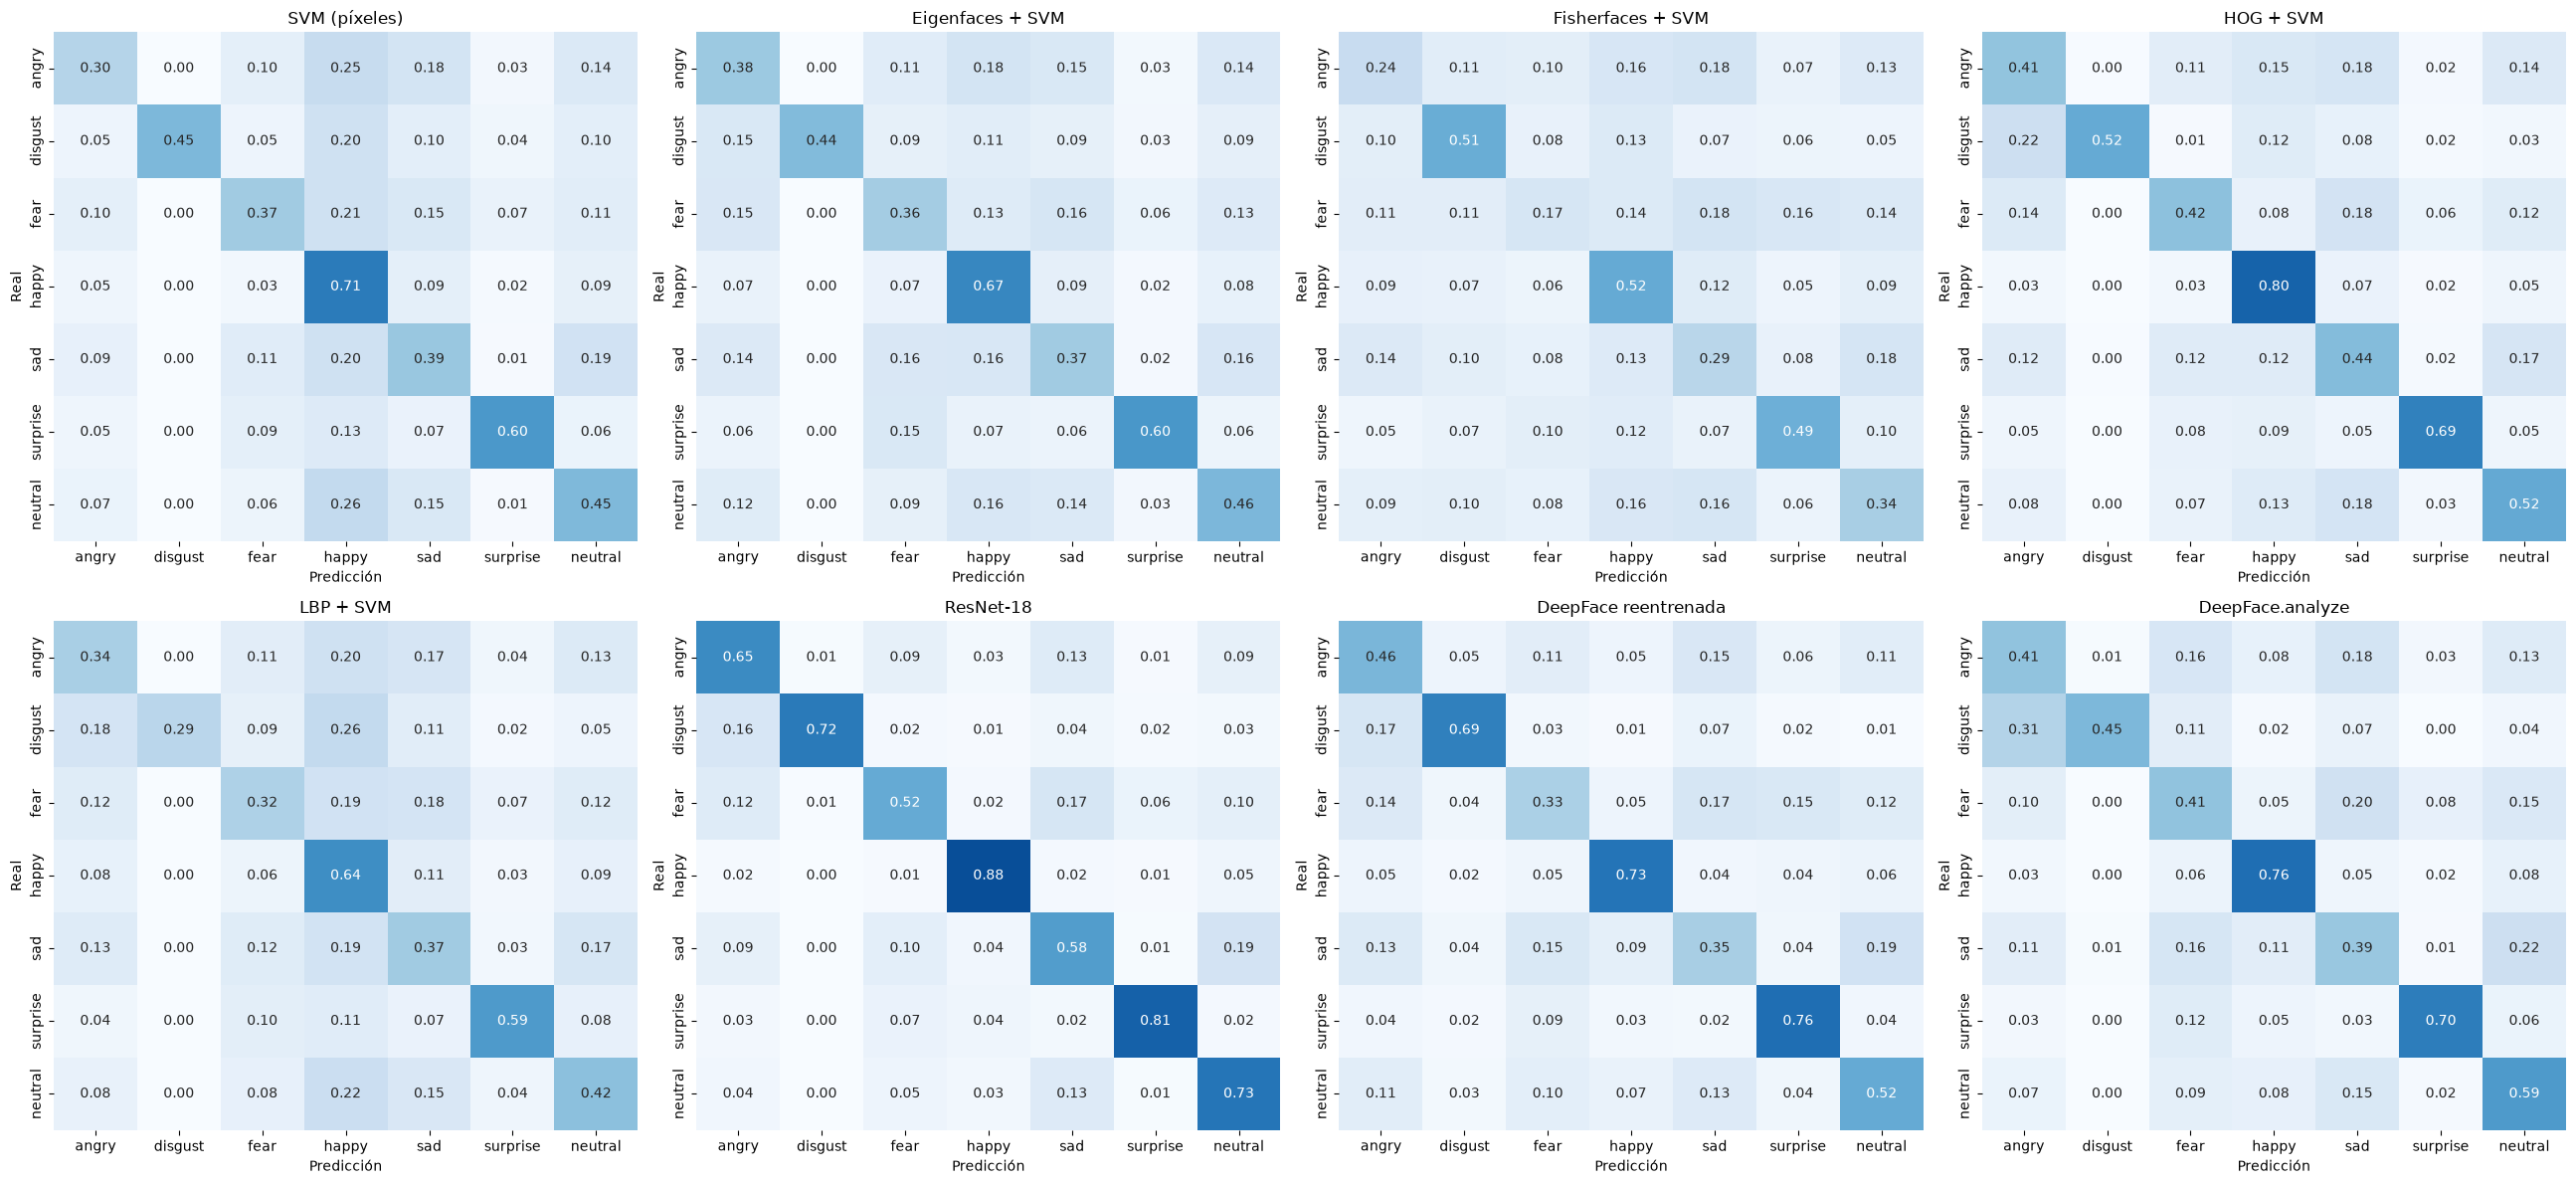

In [14]:
test = splits["FER2013"][1]
fig, axes = plt.subplots(2, 4, figsize=(26, 12))
for ax, name in zip(axes.flat, MODELS):
    runs = results[("FER2013", name)]
    plot_confusion_matrix(np.tile(fer2013_labels[test], len(runs)), np.concatenate([run["test_pred"] for run in runs]),
                          EMOTIONS, name, ax)
plt.savefig(RESULTS_DIR / "matrices_confusion.png", dpi=120)
plt.show()

### 4.3 Robustez

Al detectar en tiempo real, las caras existentes podrían contar con ruido, desenfoque, oclusiones... Para comprobar cómo afectan estas variaciones a cada modelo, se realiza nuevamente la inferencia tras alterar las imágenes del _PrivateTest_, incluyendo desenfoques, reducciones de resolución, ruido, cambios en contraste y oclusiones sobre ojos y boca.

Se evalúa de esta forma la robustez de cada modelo, en su mejor _fold_. La siguiente tabla muestra la caída de F1-macro tras incluir las distintas alteraciones sobre las caras originales:

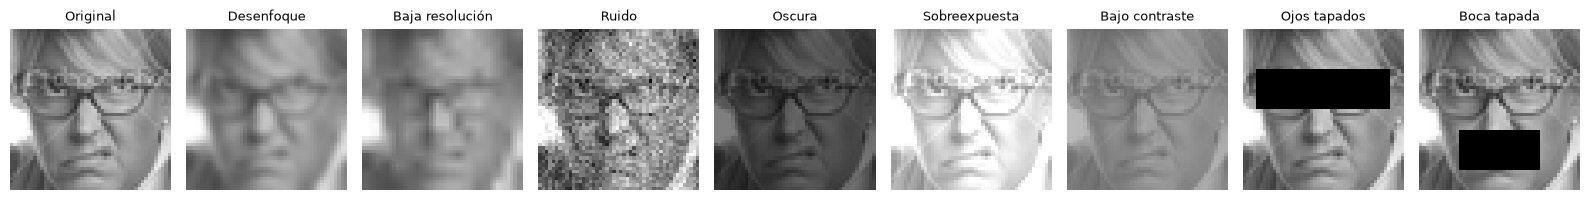

,Original,Desenfoque,Baja resolución,Ruido,Oscura,Sobreexpuesta,Bajo contraste,Ojos tapados,Boca tapada
SVM (píxeles),0.504,-0.002,-0.022,-0.005,-0.304,-0.291,-0.234,-0.361,-0.349
Eigenfaces + SVM,0.485,+0.003,-0.022,+0.004,-0.223,-0.076,-0.169,-0.318,-0.321
Fisherfaces + SVM,0.319,-0.012,-0.021,-0.001,-0.156,-0.087,-0.095,-0.219,-0.202
HOG + SVM,0.563,-0.107,-0.239,-0.292,+0.000,-0.059,+0.000,-0.368,-0.367
LBP + SVM,0.452,-0.267,-0.298,-0.337,-0.010,-0.237,-0.036,-0.396,-0.362
ResNet-18,0.698,-0.158,-0.409,-0.586,-0.005,-0.057,-0.014,-0.314,-0.323
DeepFace reentrenada,0.492,-0.097,-0.185,-0.109,-0.038,-0.065,-0.066,-0.341,-0.314
DeepFace.analyze,0.543,-0.184,-0.268,-0.075,-0.056,-0.098,-0.157,-0.422,-0.397


In [15]:
fig, axes = plt.subplots(1, len(PERTURBATIONS), figsize=(16, 2.3))
for ax, (title, perturb) in zip(axes, PERTURBATIONS.items()):
    ax.imshow(perturb(images[test[:1]])[0], cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


def robustness():
    return pd.DataFrame({title: {name: f1_score(fer2013_labels[test], best_models[("FER2013", name)].predict(perturb(images[test])),
                                                average="macro") for name in MODELS}
                         for title, perturb in PERTURBATIONS.items()})


robust = cached(WEIGHTS_DIR / "robustez.joblib", robustness)
robust.to_csv(RESULTS_DIR / "robustez.csv")
drop = robust.drop(columns="Original").sub(robust["Original"], axis=0)
display(pd.concat([robust[["Original"]], drop], axis=1).style
        .format("{:.3f}", subset=["Original"]).format("{:+.3f}", subset=list(drop.columns))
        .background_gradient(cmap="Reds_r", vmin=drop.values.min(), vmax=0, subset=list(drop.columns)))

### 4.4 Coste

Además de los análisis ya realizados, también es importante comparar el coste de los distintos modelos. Se mide el coste, tanto de entrenamiento (tiempo medio por _fold_) como de uso (tamaño del modelo guardado y velocidad de predicción). Cada modelo se mide en CPU y, si lo admite, también en GPU, usando el mejor _fold_ de cada uno en FER2013.

In [ ]:
def devices(name, model):
    if name == "DeepFace.analyze":
        return {"CPU": lambda: DeepFaceAnalyze("cpu"), "GPU": lambda: DeepFaceAnalyze("cuda")}
    if isinstance(model, TorchEmotionPredictor):
        return {"CPU": lambda: TorchEmotionPredictor(copy.deepcopy(model.model).cpu()), "GPU": lambda: model}
    return {"CPU": lambda: model}


def model_mb(name, model):
    if name == "DeepFace.analyze":
        return (Path.home() / ".deepface" / "weights" / "facial_expression_model_weights.pth").stat().st_size / 1e6
    return len(pickle.dumps(model)) / 1e6


face = images[test[:1]]
cost = {}
for name in MODELS:
    model = best_models[("FER2013", name)]
    row = {"Entrenamiento (min/fold)": np.mean([run["seconds"] for run in results[("FER2013", name)]]) / 60,
           "Tamaño (MB)": model_mb(name, model)}
    for device, make in devices(name, model).items():
        predictor = make()
        sync = torch.cuda.synchronize if device == "GPU" else None
        row[f"1 cara {device} (ms)"] = measure_latency(lambda: predictor.predict(face), cfg.timing.iters,
                                                       cfg.timing.warmup, sync)["mean_ms"]
        if device == "GPU":
            predictor.predict(images[test])
        start = time.perf_counter()
        predictor.predict(images[test])
        row[f"Lote {device} (caras/s)"] = len(test) / (time.perf_counter() - start)
    cost[name] = row
cost = pd.DataFrame(cost).T[["Entrenamiento (min/fold)", "Tamaño (MB)", "1 cara CPU (ms)", "1 cara GPU (ms)",
                             "Lote CPU (caras/s)", "Lote GPU (caras/s)"]]
cost.to_csv(RESULTS_DIR / "coste.csv")
display(cost.style.format(precision=1, na_rep="—"))

,Entrenamiento (min/fold),Tamaño (MB),1 cara CPU (ms),1 cara GPU (ms),Lote CPU (caras/s),Lote GPU (caras/s)
SVM (píxeles),161.5,460.1,28.0,—,39.0,—
Eigenfaces + SVM,10.2,24.3,1.5,—,785.9,—
Fisherfaces + SVM,6.1,5.5,1.1,—,1360.0,—
HOG + SVM,47.3,174.7,6.7,—,134.7,—
LBP + SVM,21.8,74.3,3.0,—,367.3,—
ResNet-18,2.3,44.8,4.1,2.3,848.5,18109.2
DeepFace reentrenada,0.2,6.0,0.9,0.6,2559.4,97500.4
DeepFace.analyze,—,5.9,1.2,1.7,793.7,710.5


## 5. Conclusiones

El modelo escogido debe reconocer la emoción de una cara de la _webcam_ en tiempo real, y mantenerse estable ante cambios en la imagen.

Se elige **ResNet-18 entrenada con FER+**. Este modelo cuenta con los mejores resultados, con un F1-macro de 74.8% en FER+ (70.3% en FER2013), frente a 59.8% del mejor modelo clásico (HOG + SVM) y 47.2% de `DeepFace.analyze`. Las etiquetas de FER+, menos ruidosas, mejoran a todos los modelos. Aun así, el _dataset_ limita la obtención de mejores resultados, pues las imágenes están desbalanceadas entre clases, y todas están perfectamente encuadradas en el cuadrado 48x48.

ResNet-18 es también el modelo más robusto en la mayoría de alteraciones: es el mejor en 6 de las 8, y apenas le afectan la luz y el contraste. Sus mayores debilidades son el ruido y la baja resolución.

Con unos 4 ms por cara en CPU (2 ms en GPU), su coste es perfectamente asumible en _real-time_.